In [4]:
from sklearn.datasets import make_regression
import numpy as np
import matplotlib.pyplot as plt 
from sklearn.model_selection import cross_val_score

In [2]:
X, y = make_regression(n_samples=100, n_features=1, n_informative=1,n_targets=1, noise=10, random_state=20)

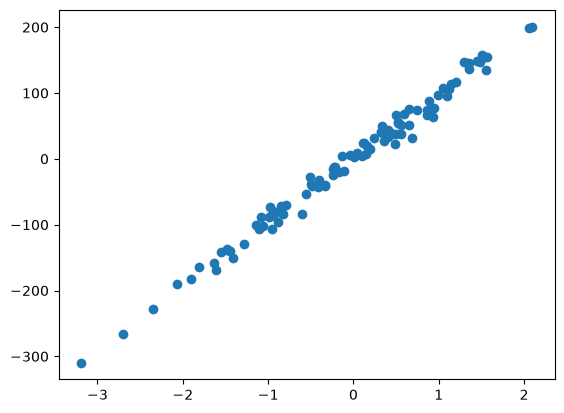

In [3]:
plt.scatter(X,y)

In [8]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

In [9]:
lr.fit(X,y)
print(lr.coef_)
print(lr.intercept_)

[96.25266223]
1.1456486284580158


In [10]:
np.mean(cross_val_score(lr, X, y, cv=5, scoring='r2'))

np.float64(0.9888331270631582)

In [40]:
m = 96.25

In [16]:
class GDRegressor:
    def __init__(self, learning_rate, epochs):
        self.m = 100
        self.b = -120
        self.lr = learning_rate
        self.epochs = epochs   
        
    def fit(self, X, y):
        # calculate the b using GD
        for i in range(self.epochs):
            loss_slope_b = -2 * np.sum(y - self.m*X.ravel() - self.b)
            loss_slope_m = -2 * np.sum((y - self.m*X.ravel() - self.b) * X.ravel())
            self.b = self.b - (self.lr * loss_slope_b)
            self.m = self.m - (self.lr * loss_slope_m)
        print(self.b)
        print(self.m)
    
    def predict(self, X):
        return self.m * X + self.b
            

In [17]:
gd = GDRegressor(0.001, 50)

In [18]:
gd.fit(X, y)

1.1436984257365088
96.25210784562479


In [19]:
gd.predict(X)

array([[-155.69925743],
       [ -48.24759965],
       [-135.21346222],
       [ 152.03163597],
       [  54.49382906],
       [ -52.29410477],
       [ 131.25693082],
       [-148.15301683],
       [ -20.83268204],
       [ -79.93599082],
       [ -46.34813899],
       [  51.93867606],
       [  67.65410887],
       [ 129.42641025],
       [ 199.40744789],
       [  10.65231082],
       [  48.05726078],
       [ 131.83375313],
       [   4.81980405],
       [-154.11001   ],
       [ -19.99914761],
       [ -37.79355408],
       [  35.55734171],
       [  16.14345578],
       [ -78.61972747],
       [  91.56960361],
       [-141.53898729],
       [  32.27750244],
       [  19.99611965],
       [-197.80447294],
       [-181.87622454],
       [-141.85994555],
       [  51.87526977],
       [  32.03781298],
       [ 102.31512441],
       [  96.38386538],
       [ -22.27817073],
       [ -81.26391223],
       [-173.57849938],
       [  63.42209282],
       [ 106.5814675 ],
       [ -15.088

In [20]:
np.mean(cross_val_score(gd, X, y, scoring='r2', cv=10))

AttributeError: The following error was raised: 'GDRegressor' object has no attribute '__sklearn_tags__'. It seems that there are no classes that implement `__sklearn_tags__` in the MRO and/or all classes in the MRO call `super().__sklearn_tags__()`. Make sure to inherit from `BaseEstimator` which implements `__sklearn_tags__` (or alternatively define `__sklearn_tags__` but we don't recommend this approach). Note that `BaseEstimator` needs to be on the right side of other Mixins in the inheritance order.